<a href="https://colab.research.google.com/github/aarushipandey06/Kepler-s-Laws/blob/main/Kepler's%20Second%20Law.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computational Study of Planetary Motion

This notebook follows the report: physical model, Euler method, Kepler's second law, phase-space analysis, JPL data validation, and comparison of Euler, RK4, and velocity Verlet.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 1. Physical Model and Euler Method

In [ ]:
MU = 4*np.pi**2  # AU^3/year^2
a, e = 1.0, 0.2
x0, y0, vx0 = a*(1-e), 0.0, 0.0
vy0 = np.sqrt(MU*(1+e)/(a*(1-e)))
total_time = 1.0

print(f"x0 = {x0:.4f} AU, y0 = {y0:.4f} AU")
print(f"vx0 = {vx0:.4f} AU/year, vy0 = {vy0:.4f} AU/year")


x0 = 0.8000 AU, y0 = 0.0000 AU
vx0 = 0.0000 AU/year, vy0 = 7.6953 AU/year


## 2. Idealized Model and Initial Conditions

In [ ]:
def acceleration(x, y):
    r = np.sqrt(x**2 + y**2)
    return -MU*x/r**3, -MU*y/r**3

def euler_method(x0, y0, vx0, vy0, dt, total_time):
    n = int(round(total_time/dt))
    t = np.arange(n+1)*dt
    x, y, vx, vy = [np.zeros(n+1) for _ in range(4)]
    x[0], y[0], vx[0], vy[0] = x0, y0, vx0, vy0

    for i in range(n):
        ax, ay = acceleration(x[i], y[i])
        x[i+1], y[i+1] = x[i]+vx[i]*dt, y[i]+vy[i]*dt
        vx[i+1], vy[i+1] = vx[i]+ax*dt, vy[i]+ay*dt
    return t, x, y, vx, vy

## 2.1. Kepler's Second Law: Convergence Analysis

In [ ]:
dt_values = [1e-2, 5e-3, 1e-3, 5e-4, 1e-4, 5e-5, 1e-5, 5e-6, 1e-6]
previous_K = None
print("dt (year)    Mean K       Change (%)\n"+"-"*38)

for dt in dt_values:
    _, xx, yy, _, _ = euler_method(x0,y0,vx0,vy0,dt,total_time)
    K_mean = np.mean(0.5*np.abs(xx[:-1]*yy[1:]-yy[:-1]*xx[1:])/dt)
    change = 0 if previous_K is None else abs(K_mean-previous_K)/abs(previous_K)*100
    print(f"{dt:.1e}     {K_mean:.8f}    {change:.6f}")
    previous_K = K_mean

dt (year)    Mean K       Change (%)
--------------------------------------
1.0e-02     3.55708214    0.000000
5.0e-03     3.34039875    6.091605
1.0e-03     3.13880460    6.035032
5.0e-04     3.10936213    0.938015
1.0e-04     3.08453423    0.798489
5.0e-05     3.08133807    0.103619
1.0e-05     3.07876510    0.083502
5.0e-06     3.07844246    0.010480
1.0e-06     3.07818418    0.008390


## 2.2. Final Kepler Verification

In [ ]:
dt_main = 1e-6
t, x, y, vx, vy = euler_method(x0,y0,vx0,vy0,dt_main,total_time)
swept_area=np.abs(x[:-1]*y[1:]-y[:-1]*x[1:])
K = 0.5*(swept_area)/dt_main
K_mean = np.mean(K)
K_theory = 0.5*np.sqrt(MU*a*(1-e**2))
variation = np.max(np.abs(K-K_mean))/abs(K_mean)*100
theory_error = abs(K_mean-K_theory)/abs(K_theory)*100

print("\nSelected numerical areal velocities:")
print("Time (yr)     x (AU)       y (AU)       Swept Area (AU²)    K (AU²/yr)")
print("-" * 80)

# Print 10 evenly spaced values
indices = np.linspace(
    0, len(K) - 1, 10, dtype=int
)

for i in indices:
    print(
        f"{t[i]:.6f}   "
        f"{x[i]:.8f}   "
        f"{y[i]:.8f}   "
        f"{swept_area[i]:.8f}       "
        f"{K[i]:.8f}"
    )

print("--"*40)
print(f"Mean K = {K_mean:.8f} AU^2/year")
print(f"Theoretical K = {K_theory:.8f} AU^2/year")
print(f"Maximum variation = {variation:.6f}%")
print(f"Error from theory = {theory_error:.6f}%")


Selected numerical areal velocities:
Time (yr)     x (AU)       y (AU)       Swept Area (AU²)    K (AU²/yr)
--------------------------------------------------------------------------------
0.000000   0.80000000   0.00000000   0.00000616       3.07811959
0.111111   0.46138118   0.73490196   0.00000616       3.07814385
0.222222   -0.22539513   0.97949479   0.00000616       3.07816055
0.333333   -0.82818434   0.76238483   0.00000616       3.07817167
0.444444   -1.15782640   0.28171631   0.00000616       3.07818025
0.555555   -1.15788704   -0.28157215   0.00000616       3.07818812
0.666666   -0.82836788   -0.76229325   0.00000616       3.07819670
0.777777   -0.22568542   -0.97954336   0.00000616       3.07820782
0.888888   0.46110768   -0.73521426   0.00000616       3.07822452
0.999999   0.80005861   -0.00052244   0.00000616       3.07824876
--------------------------------------------------------------------------------
Mean K = 3.07818418 AU^2/year
Theoretical K = 3.07811959 AU^2/year
M

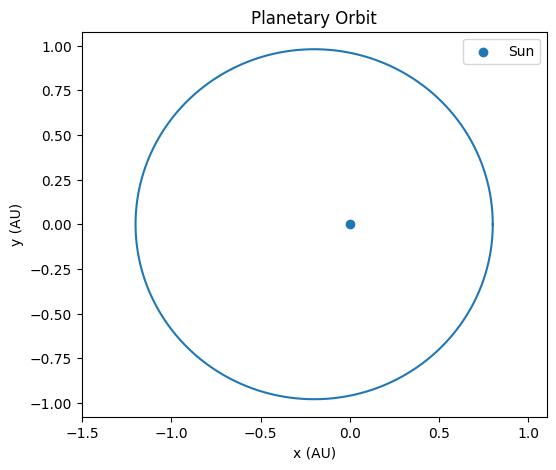

In [ ]:
plt.figure(figsize=(6,5)); plt.plot(x,y); plt.scatter(0,0,label="Sun")
plt.xlabel("x (AU)"); plt.ylabel("y (AU)"); plt.title("Planetary Orbit")
plt.axis("equal"); plt.legend(); plt.show()

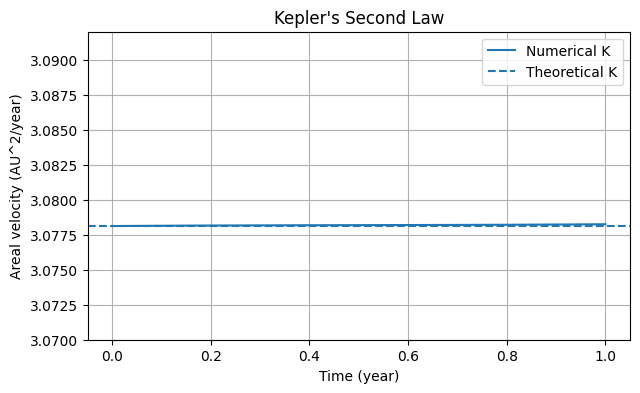

In [ ]:
plt.figure(figsize=(7,4)); plt.plot(t[:-1],K,label="Numerical K")
plt.axhline(K_theory,ls="--",label="Theoretical K")
plt.xlabel("Time (year)"); plt.ylabel("Areal velocity (AU^2/year)")
plt.title("Kepler's Second Law"); plt.ylim(3.070,3.092)
plt.legend(); plt.grid(); plt.show()

## 3. Phase-Space Analysis

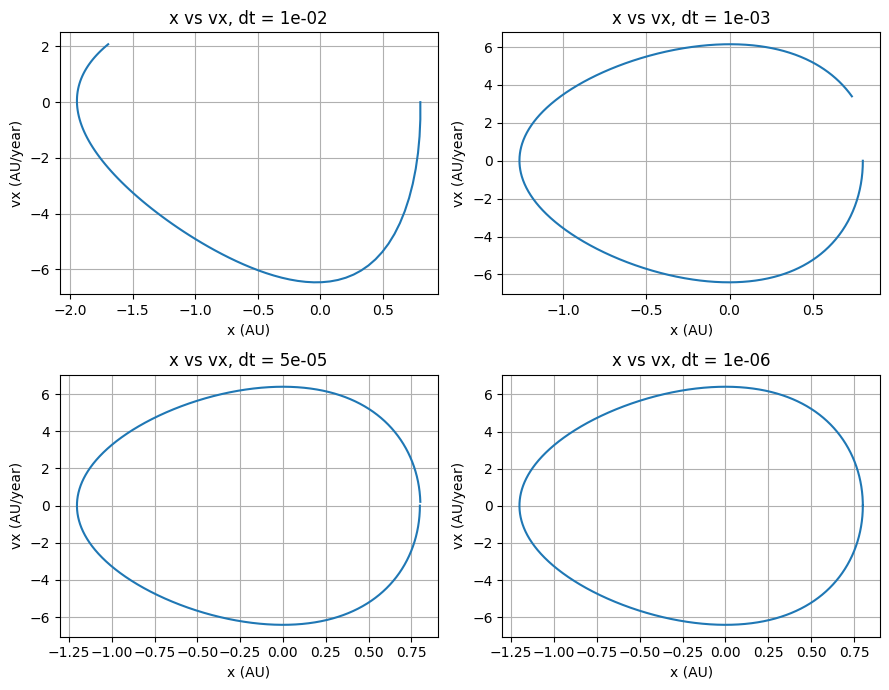

In [ ]:
dt_values = [1e-2, 1e-3, 5e-5, 1e-6]
fig, axes = plt.subplots(2,2,figsize=(9,7))

for ax, dt in zip(axes.ravel(), dt_values):
    _, xx, yy, vxx, vyy = euler_method(x0,y0,vx0,vy0,dt,total_time)
    ax.plot(xx,vxx); ax.set_title(f"x vs vx, dt = {dt:.0e}")
    ax.set_xlabel("x (AU)"); ax.set_ylabel("vx (AU/year)"); ax.grid()

plt.tight_layout(); plt.show()

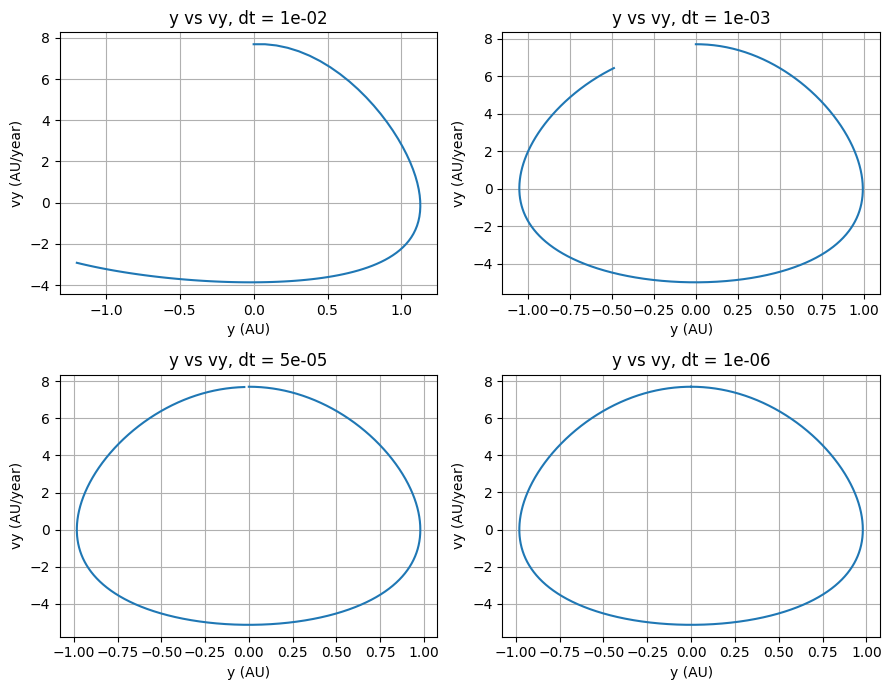

In [ ]:
dt_values = [1e-2, 1e-3, 5e-5, 1e-6]
fig, axes = plt.subplots(2,2,figsize=(9,7))

for ay, dt in zip(axes.ravel(), dt_values):
    _, xx, yy, vxx, vyy = euler_method(x0,y0,vx0,vy0,dt,total_time)
    ay.plot(yy,vyy); ay.set_title(f"y vs vy, dt = {dt:.0e}")
    ay.set_xlabel("y (AU)"); ay.set_ylabel("vy (AU/year)"); ay.grid()

plt.tight_layout(); plt.show()

## 4.1. JPL Real Data: Convergence Analysis

In [ ]:
jpl_days = np.array([0,36,72,108,144,180,216,252,288,324,360])
jpl_times = jpl_days/365.25


jpl_x_km = np.array([
    -2.653100241556548E7,
    -1.080091974038405E8,
    -1.480030443423478E8,
    -1.322585295482711E8,
    -6.801125386665048E7,
     2.058137778623243E7,
     1.017948816384978E8,
     1.465669417595046E8,
     1.378548678844599E8,
     7.751058403303044E7,
    -1.255045076178773E7
])

jpl_y_km = np.array([
     1.439468995740296E8,
     1.000903106437828E8,
     1.717356117508375E7,
    -7.271240297578754E7,
    -1.363410587539120E8,
    -1.514370775752981E8,
    -1.131295643365498E8,
    -3.479899534238102E7,
     5.578021091609459E7,
     1.250133915540625E8,
     1.458646385442073E8
])

jpl_vx_kms = np.array([
    -2.977650610770464E1,
    -2.085138152363809E1,
    -4.086588222194061E0,
     1.379379990964837E1,
     2.617900873159191E1,
     2.902365045733154E1,
     2.158481101855345E1,
     6.260466267006428E0,
    -1.177616918840351E1,
    -2.581704638821091E1,
    -3.014720865232916E1
])

jpl_vy_kms = np.array([
    -5.395962660572101E0,
    -2.182594475833216E1,
    -2.968485564088994E1,
    -2.627410558624421E1,
    -1.340943733799162E1,
     3.975096989659099E0,
     1.990986449167997E1,
     2.892285536796816E1,
     2.745986051047800E1,
     1.553101970932042E1,
    -2.617680928311538E0
])

KM_PER_AU, SECONDS_PER_YEAR = 149597870.7, 365.25*86400
jpl_x, jpl_y = jpl_x_km/KM_PER_AU, jpl_y_km/KM_PER_AU
jpl_vx = jpl_vx_kms*SECONDS_PER_YEAR/KM_PER_AU
jpl_vy = jpl_vy_kms*SECONDS_PER_YEAR/KM_PER_AU
x0_jpl, y0_jpl, vx0_jpl, vy0_jpl = jpl_x[0], jpl_y[0], jpl_vx[0], jpl_vy[0]

# Time-step convergence
dt_values_jpl = [1e-2,5e-3,1e-3,5e-4,1e-4,5e-5,1e-5,5e-6,1e-6]
total_time_jpl = 360/365.25
previous_x = previous_y = None
print("dt (yr)       Final Position Change (%)\n"+"-"*50)

for dt in dt_values_jpl:
    _, xx, yy, _, _ = euler_method(x0_jpl,y0_jpl,vx0_jpl,vy0_jpl,dt,total_time_jpl)
    xf, yf = xx[-1], yy[-1]
    if previous_x is None:
        change = 0
    else:
        change = np.hypot(xf-previous_x,yf-previous_y)/np.hypot(previous_x,previous_y)*100
    print(f"{dt:.1e}       {change:.8f}")
    previous_x, previous_y = xf, yf

dt (yr)       Final Position Change (%)
--------------------------------------------------
1.0e-02       0.00000000
5.0e-03       60.29144405
1.0e-03       84.41237769
5.0e-04       16.59132156
1.0e-04       14.74235989
5.0e-05       1.97310660
1.0e-05       1.55468411
5.0e-06       0.19385811
1.0e-06       0.15842054


## 4.2. JPL Real Data: Validation

In [ ]:
dt_jpl = 1e-6
total_time_jpl = 360/365.25

t_euler, x_euler, y_euler, vx_euler, vy_euler = euler_method(
    x0_jpl, y0_jpl, vx0_jpl, vy0_jpl,
    dt_jpl, total_time_jpl
)

print(f"Time step = {dt_jpl:.1e} year")

# Match Euler results to the JPL observation times
x_sim = np.interp(jpl_times, t_euler, x_euler)
y_sim = np.interp(jpl_times, t_euler, y_euler)

# Position error
position_difference = np.sqrt((x_sim - jpl_x)**2 + (y_sim - jpl_y)**2)
jpl_radius = np.sqrt(jpl_x**2 + jpl_y**2)

position_error = position_difference/jpl_radius*100

# Radial distance error
r_sim = np.sqrt(x_sim**2 + y_sim**2)
r_jpl = np.sqrt(jpl_x**2 + jpl_y**2)

radial_error = np.abs(r_sim - r_jpl)/r_jpl*100

print("Day   Position Error (%)   Radial Error (%)")
print("-" * 45)

for day, pe, re in zip(jpl_days, position_error, radial_error):
    print(f"{day:3.0f}      {pe:10.6f}       {re:10.6f}")

print(f"\nMaximum position error = {np.max(position_error):.6f}%")
print(f"Maximum radial error = {np.max(radial_error):.6f}%")
print(f"Final position error = {position_error[-1]:.6f}%")
print(f"Final radial error = {radial_error[-1]:.6f}%")

Time step = 1.0e-06 year
Day   Position Error (%)   Radial Error (%)
---------------------------------------------
  0        0.000000         0.000000
 36        0.226291         0.225741
 72        0.820225         0.782749
108        1.799456         1.450724
144        3.213876         2.005916
180        5.015459         2.293733
216        7.017163         2.234686
252        8.936634         1.827379
288       10.469755         1.168977
324       11.385414         0.472056
360       11.649850         0.007723

Maximum position error = 11.649850%
Maximum radial error = 2.293733%
Final position error = 11.649850%
Final radial error = 0.007723%


## 5. Comparison of Euler, RK4, and Velocity Verlet

,Method,Maximum Position Error (%),Final Position Error (%),Maximum Energy Error (%)
0,Euler,0.06476,0.06476,0.008917
1,RK4,0.00000,0.00000,0.000000
2,Velocity Verlet,0.00000,0.00000,0.000000


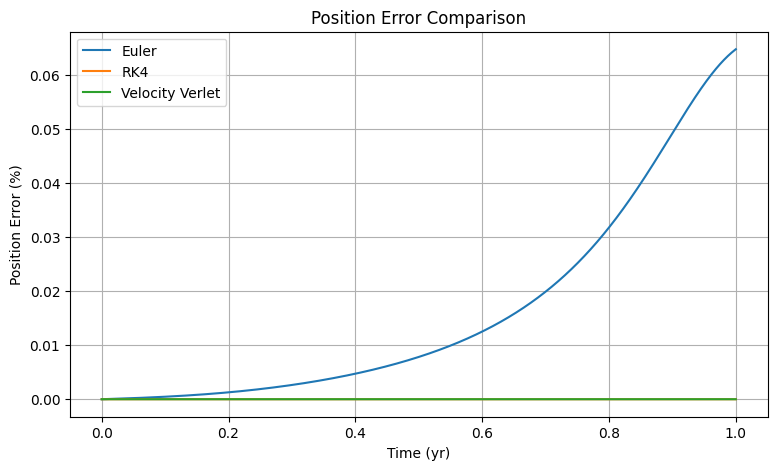

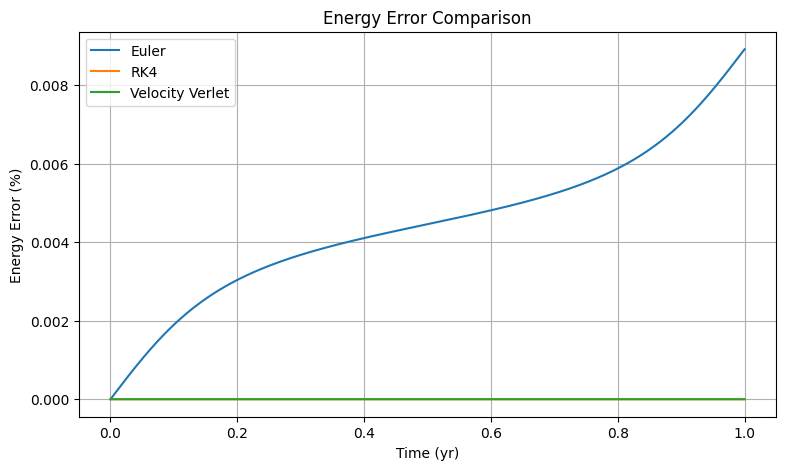

In [ ]:
def rk4_method(x0,y0,vx0,vy0,dt,total_time):
    t = np.arange(0,total_time+dt,dt)
    values = np.zeros((len(t),4)); values[0] = [x0,y0,vx0,vy0]

    def f(s):
        x,y,vx,vy = s; r = np.hypot(x,y)
        return np.array([vx,vy,-MU*x/r**3,-MU*y/r**3])

    for i in range(len(t)-1):
        s = values[i]
        k1 = f(s); k2 = f(s+dt*k1/2); k3 = f(s+dt*k2/2); k4 = f(s+dt*k3)
        values[i+1] = s + dt*(k1+2*k2+2*k3+k4)/6
    return t, values[:,0], values[:,1], values[:,2], values[:,3]

def velocity_verlet_method(x0,y0,vx0,vy0,dt,total_time):
    t = np.arange(0,total_time+dt,dt)
    x,y,vx,vy = [np.zeros(len(t)) for _ in range(4)]
    x[0],y[0],vx[0],vy[0] = x0,y0,vx0,vy0

    for i in range(len(t)-1):
        ax,ay = acceleration(x[i],y[i])
        x[i+1] = x[i]+vx[i]*dt+0.5*ax*dt**2
        y[i+1] = y[i]+vy[i]*dt+0.5*ay*dt**2
        ax2,ay2 = acceleration(x[i+1],y[i+1])
        vx[i+1] = vx[i]+0.5*(ax+ax2)*dt
        vy[i+1] = vy[i]+0.5*(ay+ay2)*dt
    return t,x,y,vx,vy

dt, total_time = 1e-6, 1.0
t = np.arange(0,total_time+dt,dt)
n = np.sqrt(MU/a**3); M = n*t; E = M.copy()
for _ in range(20):
    E -= (E-e*np.sin(E)-M)/(1-e*np.cos(E))
x_exact = a*(np.cos(E)-e)
y_exact = a*np.sqrt(1-e**2)*np.sin(E)

t_e,x_e,y_e,vx_e,vy_e = euler_method(x0,y0,vx0,vy0,dt,total_time)
t_rk,x_rk,y_rk,vx_rk,vy_rk = rk4_method(x0,y0,vx0,vy0,dt,total_time)
t_vv,x_vv,y_vv,vx_vv,vy_vv = velocity_verlet_method(x0,y0,vx0,vy0,dt,total_time)

def position_error(x,y):
    return np.hypot(x-x_exact,y-y_exact)/np.hypot(x_exact,y_exact)*100

def energy(x,y,vx,vy):
    return 0.5*(vx**2+vy**2)-MU/np.hypot(x,y)

def energy_error(x,y,vx,vy):
    E = energy(x,y,vx,vy)
    return abs((E-E[0])/E[0])*100

errors = [position_error(*v) for v in [(x_e,y_e),(x_rk,y_rk),(x_vv,y_vv)]]
energies = [energy_error(*v) for v in [(x_e,y_e,vx_e,vy_e),
 (x_rk,y_rk,vx_rk,vy_rk),(x_vv,y_vv,vx_vv,vy_vv)]]

summary = pd.DataFrame({
    "Method":["Euler","RK4","Velocity Verlet"],
    "Maximum Position Error (%)":[np.max(z) for z in errors],
    "Final Position Error (%)":[z[-1] for z in errors],
    "Maximum Energy Error (%)":[np.max(z) for z in energies]
})
display(summary.round(6))

for values, title, ylabel in [(errors,"Position Error Comparison","Position Error (%)"),
                              (energies,"Energy Error Comparison","Energy Error (%)")]:
    plt.figure(figsize=(9,5))
    for z,label in zip(values,["Euler","RK4","Velocity Verlet"]): plt.plot(t,z,label=label)
    plt.xlabel("Time (yr)"); plt.ylabel(ylabel); plt.title(title)
    plt.legend(); plt.grid(); plt.show()